1. Setup and Data Loading

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", None)

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

Project root: /Users/charlenephua/Library/Mobile Documents/com~apple~CloudDocs/uni/Y4/y4s1/bt4012/bt4012-fraud-detection
Data directory: /Users/charlenephua/Library/Mobile Documents/com~apple~CloudDocs/uni/Y4/y4s1/bt4012/bt4012-fraud-detection/data/raw


In [2]:
#Reading the data

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
edges = pd.read_csv(DATA_DIR / "txs_edgelist.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Edges shape:", edges.shape)
print("Submission shape:", sample_submission.shape)

Train shape: (141772, 168)
Test shape: (15329, 168)
Edges shape: (234355, 2)
Submission shape: (15329, 2)


2. EDA

2.1 Dataset overview

In [3]:
#Column definitions
ID_COL = "txId"
TIME_COL = "time_step"
TARGET = "label"

In [4]:
#Examining the data

display(train.head())
display(test.head())
display(edges.head())
display(sample_submission.head())

,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,feat_10,feat_11,feat_12,feat_13,feat_14,feat_15,feat_16,feat_17,feat_18,feat_19,feat_20,feat_21,feat_22,feat_23,feat_24,feat_25,feat_26,feat_27,feat_28,feat_29,feat_30,feat_31,feat_32,feat_33,feat_34,feat_35,feat_36,feat_37,feat_38,feat_39,feat_40,feat_41,feat_42,feat_43,feat_44,feat_45,feat_46,feat_47,feat_48,feat_49,feat_50,feat_51,feat_52,feat_53,feat_54,feat_55,feat_56,feat_57,feat_58,feat_59,feat_60,feat_61,feat_62,feat_63,feat_64,feat_65,feat_66,feat_67,feat_68,feat_69,feat_70,feat_71,feat_72,feat_73,feat_74,feat_75,feat_76,feat_77,feat_78,feat_79,feat_80,feat_81,feat_82,feat_83,feat_84,feat_85,feat_86,feat_87,feat_88,feat_89,feat_90,feat_91,feat_92,feat_93,feat_94,feat_95,feat_96,feat_97,feat_98,feat_99,feat_100,feat_101,feat_102,feat_103,feat_104,feat_105,feat_106,feat_107,feat_108,feat_109,feat_110,feat_111,feat_112,feat_113,feat_114,feat_115,feat_116,feat_117,feat_118,feat_119,feat_120,feat_121,feat_122,feat_123,feat_124,feat_125,feat_126,feat_127,feat_128,feat_129,feat_130,feat_131,feat_132,feat_133,feat_134,feat_135,feat_136,feat_137,feat_138,feat_139,feat_140,feat_141,feat_142,feat_143,feat_144,feat_145,feat_146,feat_147,feat_148,feat_149,feat_150,feat_151,feat_152,feat_153,feat_154,feat_155,feat_156,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,label
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,-0.167933,-0.049707,-0.164402,-0.028741,-0.035391,-0.042955,-0.013282,-0.057195,-0.169609,-0.171154,-0.174473,-1.373657,-1.371460,-0.139731,-0.148912,-0.080147,-0.155661,-0.010763,-0.012107,-0.139733,-0.148907,-0.080147,-0.155661,-0.010669,-0.012005,-0.024669,-0.031272,-0.023045,-0.026215,0.001428,0.001483,-0.227215,-0.239368,-0.075256,-0.234952,0.037468,0.043444,-0.227203,-0.243236,-0.097895,-0.235896,0.036577,0.042345,-0.414005,-0.488340,-0.232553,-0.467554,0.048767,0.052956,-0.039149,-0.172895,-0.163126,-0.160932,-1.316342,-1.315388,-0.039144,-0.172884,-0.163115,-0.160925,-1.316333,-1.315375,-0.017032,-0.030026,-0.017640,-0.015071,-0.140763,-0.140335,-0.095403,-0.264376,-0.250523,-0.263703,1.133527,1.135947,-0.059013,-0.262368,-0.255111,-0.259194,1.125590,1.128038,-0.293773,-0.159732,0.034039,-0.183816,1.135523,1.135279,-0.169160,-0.201584,-0.116817,-0.191472,-0.014659,-0.018849,-1.457953,-1.494057,-0.083459,-1.485972,-0.088798,-0.090437,-0.166550,-0.216536,-0.134546,-0.194817,-0.003175,-0.004094,-1.096336,-1.267340,-0.349933,-1.230441,-0.004358,-0.004194,-0.116425,-0.176617,-0.137323,-0.152464,-0.026060,-0.027660,-0.093145,-0.143707,-0.097719,-0.127462,0.003143,0.002426,-0.120950,-0.199145,-0.187993,-0.212948,1.064205,1.063787,-1.373782,-1.354735,-0.297975,-1.403698,1.342003,1.340733,-0.171601,-0.458162,-0.423588,-0.440883,-1.015963,-1.016230,-0.968903,-0.375715,0.759748,-0.768329,1.488113,1.487932,-0.216814,-0.605631,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,-0.167948,-0.049707,-0.164417,-0.028741,-0.035391,-0.042955,-0.013282,-0.055327,-0.169757,-0.171477,-0.174490,0.887058,0.884557,-0.139731,-0.148912,-0.080147,-0.155661,-0.010763,-0.012107,-0.139733,-0.148907,-0.080147,-0.155661,-0.010669,-0.012005,-0.024669,-0.031272,-0.023045,-0.026215,0.001428,0.001483,-0.227215,-0.239368,-0.075256,-0.234952,0.037468,0.043444,-0.227203,-0.243236,-0.097895,-0.235896,0.036577,0.042345,-0.413965,-0.488307,-0.232553,-0.467516,0.048767,0.052956,-0.039151,-0.172895,-0.163126,-0.160933,0.923473,0.923011,-0.039146,-0.172884,-0.163114,-0.160926,0.923516,0.923110,-0.017032,-0.030026,-0.017640,-0.015071,-0.140763,-0.140335,-0.095403,-0.264425,-0.250574,-0.263753,-0.169119,-0.167165,-0.059013,-0.262424,-0.255168,-0.259251,-0.187191,-0.185274,-0.293692,-0.760700,-0.692777,-0.719789,-1.084907,-1.084845,-0.170113,-0.202332,-0.116817,-0

,index,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,feat_10,feat_11,feat_12,feat_13,feat_14,feat_15,feat_16,feat_17,feat_18,feat_19,feat_20,feat_21,feat_22,feat_23,feat_24,feat_25,feat_26,feat_27,feat_28,feat_29,feat_30,feat_31,feat_32,feat_33,feat_34,feat_35,feat_36,feat_37,feat_38,feat_39,feat_40,feat_41,feat_42,feat_43,feat_44,feat_45,feat_46,feat_47,feat_48,feat_49,feat_50,feat_51,feat_52,feat_53,feat_54,feat_55,feat_56,feat_57,feat_58,feat_59,feat_60,feat_61,feat_62,feat_63,feat_64,feat_65,feat_66,feat_67,feat_68,feat_69,feat_70,feat_71,feat_72,feat_73,feat_74,feat_75,feat_76,feat_77,feat_78,feat_79,feat_80,feat_81,feat_82,feat_83,feat_84,feat_85,feat_86,feat_87,feat_88,feat_89,feat_90,feat_91,feat_92,feat_93,feat_94,feat_95,feat_96,feat_97,feat_98,feat_99,feat_100,feat_101,feat_102,feat_103,feat_104,feat_105,feat_106,feat_107,feat_108,feat_109,feat_110,feat_111,feat_112,feat_113,feat_114,feat_115,feat_116,feat_117,feat_118,feat_119,feat_120,feat_121,feat_122,feat_123,feat_124,feat_125,feat_126,feat_127,feat_128,feat_129,feat_130,feat_131,feat_132,feat_133,feat_134,feat_135,feat_136,feat_137,feat_138,feat_139,feat_140,feat_141,feat_142,feat_143,feat_144,feat_145,feat_146,feat_147,feat_148,feat_149,feat_150,feat_151,feat_152,feat_153,feat_154,feat_155,feat_156,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165
0,0,200459281,36,-0.172879,-0.058452,0.463609,-0.121970,-0.043875,-0.113002,-0.061584,-0.163536,-0.169352,-0.049707,-0.165839,-0.028741,-0.035391,-0.042955,-0.013282,-0.057065,-0.171067,-0.172840,-0.176141,0.887058,0.884557,-0.132105,-0.144045,-0.080147,-0.149199,-0.010763,-0.012107,-0.132105,-0.144040,-0.080147,-0.149198,-0.010669,-0.012005,-0.024669,-0.031272,-0.023045,-0.026215,0.001428,0.001483,-0.211084,-0.224180,-0.075256,-0.219162,0.037468,0.043444,-0.211222,-0.227604,-0.097895,-0.220010,0.036577,0.042345,1.041317,0.722046,-0.232553,0.928888,0.048767,0.052956,-0.039151,-0.172895,-0.163126,-0.160933,0.923473,0.923011,-0.039146,-0.172884,-0.163115,-0.160926,0.923516,0.923110,-0.017032,-0.030026,-0.01764,-0.015071,-0.140763,-0.140335,-0.095403,-0.264425,-0.250574,-0.263753,-0.169119,-0.167165,-0.059013,-0.262424,-0.255168,-0.259251,-0.187191,-0.185274,-0.293853,-0.761944,-0.694210,-0.720952,1.135523,1.135279,-0.170634,-0.202741,-0.116817,-0.192915,-0.014659,-0.018849,0.801938,0.803958,-0.083459,0.805795,-0.088798,-0.090437,-0.088200,-0.156977,-0.134546,-0.119971,-0.003175,-0.004094,1.023860,0.787435,-0.349933,0.939106,-0.004358,-0.004194,-0.116425,-0.176617,-0.137323,-0.152464,-0.026060,-0.027660,-0.093145,-0.143707,-0.097719,-0.127462,0.003143,0.002426,-0.124290,-0.193567,-0.180149,-0.207226,1.064205,1.063787,0.739947,0.502358,-0.301617,0.663148,1.342003,1.340733,0.398289,4.421702,5.327376,4.467085,1.301966,1.301281,0.117111,0.669709,0.759748,0.445895,1.488113,1.487932,0.090912,1.794379,2.262621,1.947206,1.461330,1.461369,-0.098889,-0.087490,-0.084674,-0.140597,-1.760926,-1.760984
1,1,199944769,36,-0.172828,0.339970,1.018602,0.178180,-0.043875,0.222447,-0.061584,-0.163620,-0.169419,-0.049636,-0.165915,-0.684027,-0.280462,-0.042955,-0.013282,-0.057112,-0.171012,-0.172773,-0.176081,0.887058,0.884557,-0.139732,-0.148899,-0.080135,-0.155656,-1.256340,-1.350850,-0.139734,-0.148895,-0.080135,-0.155656,-1.256230,-1.350662,-0.024669,-0.031272,-0.023045,-0.026215,0.001428,0.001483,-0.227215,-0.229204,-0.054534,-0.232386,-2.497500,-2.278049,-0.227203,-0.234577,-0.071096,-0.233661,-2.454328,-2.289334,-0.414017,1.293405,2.274018,0.412020,-2.195071,-2.314499,-0.039151,-0.172895,-0.163125,-0.160932,0.923473,0.923011,-0.039146,-0.172884,-0.163114,-0.160925,0.923516,0.923110,-0.017032,-0.030026,-0.01764,-0.015071,-0.140763,-0.140335,-0.095403,-0.264229,-0.250372,-0.263555,1.133527,1.135947,-0.059013,-0.262340,-0.255082,-0.259166,1.125590,1.128038,-0.293836,0.012863,0.242795,-0.029899,1.135523,1.135279,-0.171000,-0.196295,-0.105635,-0.191358,-1.851472,-1.589295,0.801

,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206


,index,target
0,0,0.5
1,1,0.5
2,2,0.5
3,3,0.5
4,4,0.5


In [5]:
train.info()
summary = pd.DataFrame(
    {
    "dtype":train.dtypes,
    "missing_cnt":train.isna().sum(),
    "missing_pct":train.isna().mean() * 100,
    "unique_values":train.nunique()
    }
).sort_values(by="missing_pct", ascending=False)

display(summary)

<class 'pandas.DataFrame'>
RangeIndex: 141772 entries, 0 to 141771
Columns: 168 entries, txId to label
dtypes: float64(166), int64(2)
memory usage: 181.7 MB


,dtype,missing_cnt,missing_pct,unique_values
label,float64,110537,77.968146,2
feat_114,float64,0,0.000000,3260
feat_106,float64,0,0.000000,14780
feat_107,float64,0,0.000000,18604
feat_108,float64,0,0.000000,19529
...,...,...,...,...
feat_56,float64,0,0.000000,12287
feat_57,float64,0,0.000000,4945
feat_58,float64,0,0.000000,103856
feat_59,float64,0,0.000000,82467


In [6]:
#Missing Values

missing = (
    train.isna().mean().mul(100).sort_values(ascending=False)
)
display(missing[missing > 0])

label    77.968146
dtype: float64

In [7]:
#Duplicate Rows

print("Duplicate train rows:", train.duplicated().sum())
print("Duplicate test rows:", test.duplicated().sum())

Duplicate train rows: 0
Duplicate test rows: 0


2.2 Label availability


In [8]:
#Labelled/unlabelled data subsets
labelled = train[train[TARGET].notna()].copy()
unlabelled = train[train[TARGET].isna()].copy()

print("Total train nodes:", len(train))
print("Labelled nodes:", len(labelled))
print("Unlabelled nodes:", len(unlabelled))
print(f"Labelled percentage: {len(labelled)/len(train):.2%}")

Total train nodes: 141772
Labelled nodes: 31235
Unlabelled nodes: 110537
Labelled percentage: 22.03%


2.3 Target Distribution

,count,percentage
label,,
0.0,27591,88.3336
1.0,3644,11.6664


<Axes: title={'center': 'Target Distribution'}, xlabel='label'>

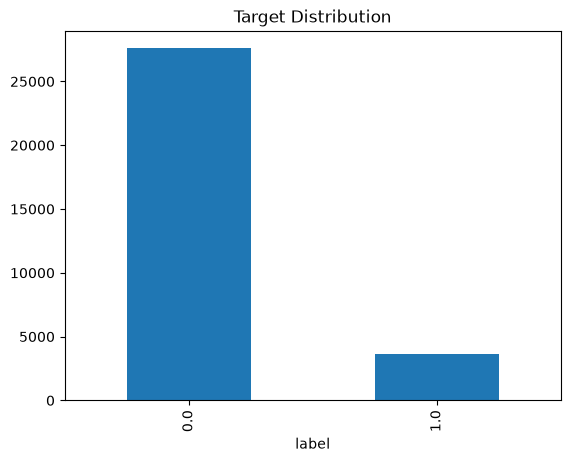

In [9]:
#Target Distribution
target_counts = train[TARGET].value_counts()
target_pct = train[TARGET].value_counts(normalize=True) * 100
display(pd.DataFrame({"count": target_counts, "percentage": target_pct}))
target_counts.plot(kind="bar", title="Target Distribution")

2.4 Temporal EDA

In [11]:
print("Train time steps:")
print(train["time_step"].value_counts().sort_index())

print("\nTest time steps:")
print(test["time_step"].value_counts().sort_index())

print("\nTrain range:",
      train["time_step"].min(),
      "to",
      train["time_step"].max())

print("Test range:",
      test["time_step"].min(),
      "to",
      test["time_step"].max())

Train time steps:
time_step
1     7880
2     4544
3     6621
4     5693
5     6803
6     4328
7     6048
8     4457
9     4996
10    6727
11    4296
12    2047
13    4528
14    2022
15    3639
16    2975
17    3385
18    1976
19    3506
20    4291
21    3537
22    5894
23    4165
24    4592
25    2314
26    2523
27    1089
28    1653
29    4275
30    2483
31    2816
32    4525
33    3151
34    2486
35    5507
Name: count, dtype: int64

Test time steps:
time_step
36    1708
37     498
38     756
39    1183
40    1211
41    1132
42    2154
43    1370
44    1591
45    1221
46     712
47     846
48     471
49     476
Name: count, dtype: int64

Train range: 1 to 35
Test range: 36 to 49


In [12]:
#labelled data over time
time_summary = (
    train.groupby("time_step")
    .agg(
        total_nodes=("txId", "size"),
        labelled_nodes=("label", "count"),
        illicit=("label", lambda x: (x == 1).sum()),
        licit=("label", lambda x: (x == 0).sum())
    )
)

time_summary["labelled_pct"] = (
    time_summary["labelled_nodes"]
    / time_summary["total_nodes"]
    * 100
)

time_summary["illicit_rate"] = (
    time_summary["illicit"]
    / time_summary["labelled_nodes"]
    * 100
)

display(time_summary)

,total_nodes,labelled_nodes,illicit,licit,labelled_pct,illicit_rate
time_step,,,,,,
1,7880,2147,17,2130,27.246193,0.791803
2,4544,1117,18,1099,24.581866,1.611459
3,6621,1279,11,1268,19.317324,0.860047
4,5693,1440,30,1410,25.294221,2.083333
5,6803,1882,8,1874,27.664266,0.425080
6,4328,485,5,480,11.206100,1.030928
7,6048,1203,102,1101,19.890873,8.478803
8,4457,1165,67,1098,26.138658,5.751073
9,4996,778,248,530,15.572458,31.876607


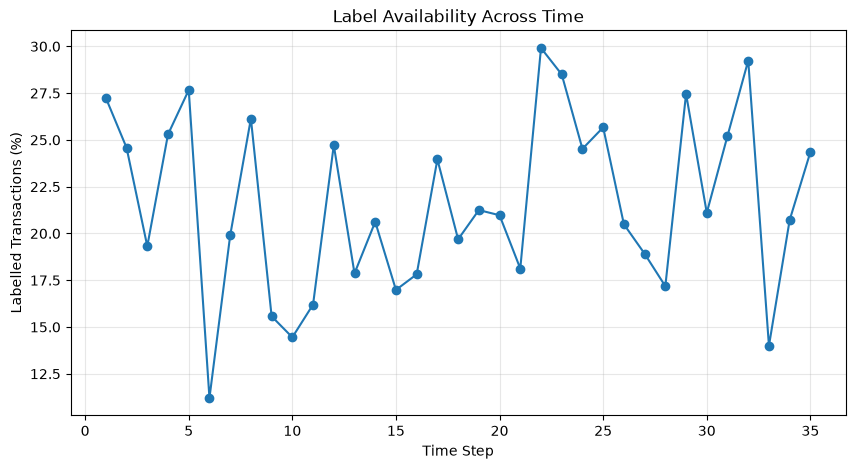

In [13]:
#labelled percentage over time
plt.figure(figsize=(10, 5))

plt.plot(
    time_summary.index,
    time_summary["labelled_pct"],
    marker="o"
)

plt.xlabel("Time Step")
plt.ylabel("Labelled Transactions (%)")
plt.title("Label Availability Across Time")
plt.grid(alpha=0.3)

plt.show()

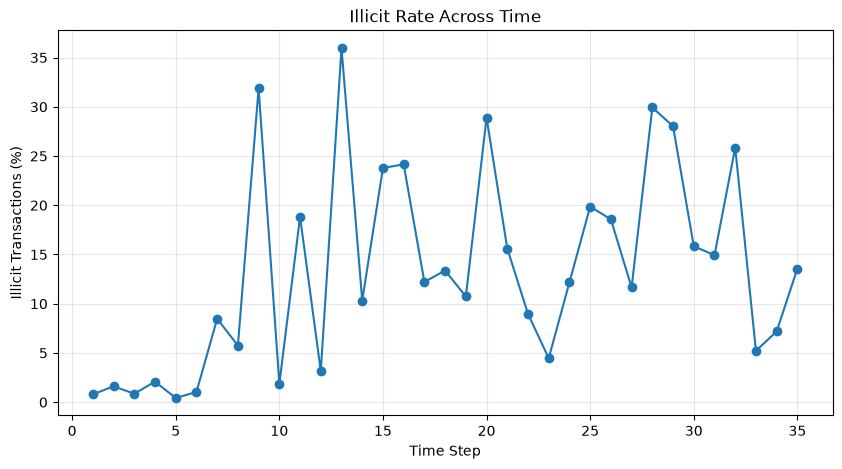

In [14]:
#illicit rate over time
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    time_summary.index,
    time_summary["illicit_rate"],
    marker="o"
)

plt.xlabel("Time Step")
plt.ylabel("Illicit Transactions (%)")
plt.title("Illicit Rate Across Time")
plt.grid(alpha=0.3)

plt.show()

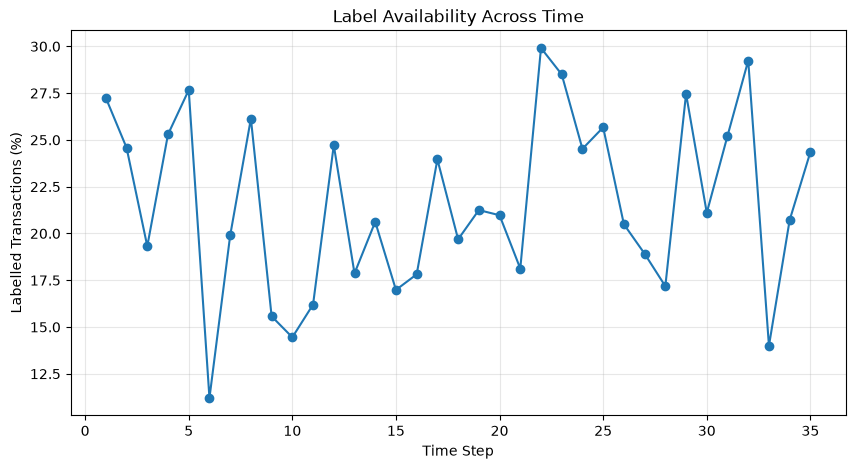

In [15]:
#labelled percentage over time
plt.figure(figsize=(10, 5))

plt.plot(
    time_summary.index,
    time_summary["labelled_pct"],
    marker="o"
)

plt.xlabel("Time Step")
plt.ylabel("Labelled Transactions (%)")
plt.title("Label Availability Across Time")
plt.grid(alpha=0.3)

plt.show()

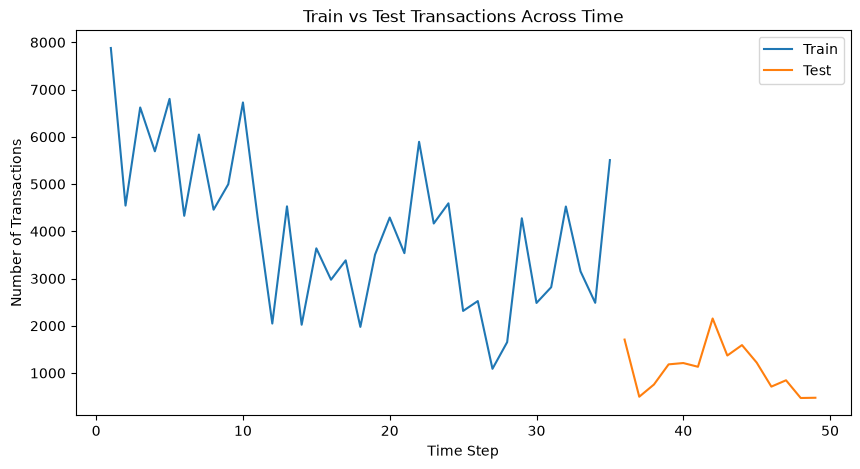

In [16]:
#train vs test transactions across time
plt.figure(figsize=(10, 5))

train["time_step"].value_counts().sort_index().plot(
    label="Train"
)

test["time_step"].value_counts().sort_index().plot(
    label="Test"
)

plt.xlabel("Time Step")
plt.ylabel("Number of Transactions")
plt.title("Train vs Test Transactions Across Time")
plt.legend()
plt.show()

2.5 Features EDA

        2.5.1 Features Overview

In [17]:
# Descriptive statistics
feature_summary = labelled[feature_cols].describe().T

feature_summary["skew"] = labelled[feature_cols].skew()
feature_summary["nunique"] = labelled[feature_cols].nunique()

display(feature_summary.head())

,count,mean,std,min,25%,50%,75%,max,skew,nunique
feat_1,31235.0,-0.073950,0.604252,-0.172982,-0.172621,-0.170475,-0.147020,25.057300,20.564378,29963
feat_2,31235.0,-0.060730,0.568019,-0.210553,-0.181302,-0.158783,-0.097065,25.674475,17.989971,6759
feat_3,31235.0,-0.199059,1.022742,-1.756361,-1.201369,-0.091383,1.018602,2.128587,0.245689,8
feat_4,31235.0,0.146563,1.560147,-0.121970,-0.121970,-0.046932,0.028105,49.027598,18.098123,193
feat_5,31235.0,0.040436,2.037377,-0.063725,-0.043875,-0.043875,-0.043875,260.090707,83.623155,103


In [10]:
#constant features
feature_cols = [
    col for col in train.columns
    if col not in [ID_COL, TIME_COL, TARGET]
]

print("Number of transaction features:", len(feature_cols))
constant_features = [
    col for col in feature_cols
    if train[col].nunique(dropna=False) <= 1
]
print("Number of constant features:", len(constant_features))
print(constant_features)

Number of transaction features: 165
Number of constant features: 0
[]


In [18]:
# Constant features
constant_features = [
    col for col in feature_cols
    if train[col].nunique(dropna=False) <= 1
]

print("Number of constant features:", len(constant_features))
print(constant_features)

# Low-cardinality features
low_cardinality = {
    col: train[col].nunique(dropna=False)
    for col in feature_cols
    if train[col].nunique(dropna=False) <= 10
}

print("\nNumber of low-cardinality features:", len(low_cardinality))
display(
    pd.DataFrame(
        low_cardinality.items(),
        columns=["feature", "unique_values"]
    ).sort_values("unique_values")
)

Number of constant features: 0
[]

Number of low-cardinality features: 5


,feature,unique_values
0,feat_3,8
1,feat_112,8
2,feat_113,8
3,feat_148,9
4,feat_149,9


In [19]:
# Most skewed features
display(
    feature_summary[
        ["mean", "std", "min", "max", "skew", "nunique"]
    ]
    .sort_values("skew", key=abs, ascending=False)
    .head(20)
)

,mean,std,min,max,skew,nunique
feat_15,-0.013149,0.008872,-0.013282,1.372120,127.102730,4
feat_34,0.039604,2.380691,-0.024669,287.891515,113.423039,488
feat_37,0.041258,2.323028,-0.026215,280.566222,113.002116,2707
feat_35,0.039793,2.245980,-0.031272,269.701184,111.185458,1618
feat_160,-0.008594,0.585977,-0.216057,58.485180,89.907542,39
feat_14,0.043011,2.077881,-0.063200,265.263236,83.623207,103
feat_5,0.040436,2.037377,-0.063725,260.090707,83.623155,103
feat_70,0.015241,1.474224,-0.017032,152.188806,81.371918,427
feat_161,0.037070,2.006631,-0.125939,251.849028,79.570641,129
feat_73,0.021638,1.660306,-0.015071,151.035179,76.404197,3461


        2.5.2 Feature-target relationship

In [20]:
#Standardized Mean Difference
#Which features individually distinguish illicit from licit transactions?

licit = labelled[labelled[TARGET] == 0]
illicit = labelled[labelled[TARGET] == 1]

smd_results = []

for col in feature_cols:
    mean_licit = licit[col].mean()
    mean_illicit = illicit[col].mean()

    std_licit = licit[col].std()
    std_illicit = illicit[col].std()

    pooled_std = np.sqrt(
        (std_licit**2 + std_illicit**2) / 2
    )

    smd = (
        (mean_illicit - mean_licit) / pooled_std
        if pooled_std > 0
        else 0
    )

    smd_results.append({
        "feature": col,
        "licit_mean": mean_licit,
        "illicit_mean": mean_illicit,
        "smd": smd,
        "abs_smd": abs(smd)
    })

smd_df = (
    pd.DataFrame(smd_results)
    .sort_values("abs_smd", ascending=False)
)

display(smd_df.head(20))

,feature,licit_mean,illicit_mean,smd,abs_smd
52,feat_53,1.193105,-0.272626,-1.276083,1.276083
88,feat_89,0.679084,-0.478488,-1.073812,1.073812
89,feat_90,0.689032,-0.518102,-1.062583,1.062583
54,feat_55,0.995756,-0.239917,-1.062165,1.062165
90,feat_91,0.641318,-0.345206,-0.849114,0.849114
53,feat_54,0.999882,-0.180328,-0.749118,0.749118
51,feat_52,0.725332,-0.193018,-0.744291,0.744291
113,feat_114,0.609604,-0.198654,-0.660097,0.660097
149,feat_150,0.002652,-0.603799,-0.635301,0.635301
147,feat_148,-0.257981,0.338396,0.590115,0.590115


In [21]:
#class differences in feature means
class_means = (
    labelled
    .groupby(TARGET)[feature_cols]
    .mean()
    .T
)

class_means.columns = ["licit_mean", "illicit_mean"]

class_means["abs_diff"] = (
    class_means["illicit_mean"]
    - class_means["licit_mean"]
).abs()

display(
    class_means
    .sort_values("abs_diff", ascending=False)
    .head(20)
)

,licit_mean,illicit_mean,abs_diff
feat_53,1.193105,-0.272626,1.465731
feat_55,0.995756,-0.239917,1.235672
feat_90,0.689032,-0.518102,1.207134
feat_54,0.999882,-0.180328,1.180210
feat_89,0.679084,-0.478488,1.157572
feat_91,0.641318,-0.345206,0.986524
feat_60,0.820402,-0.162200,0.982602
feat_66,0.820401,-0.162189,0.982589
feat_65,0.801683,-0.171890,0.973574
feat_59,0.801643,-0.171900,0.973544


In [22]:
#Single-feature ROC-AUC

from sklearn.metrics import roc_auc_score

y = labelled[TARGET].astype(int)

auc_results = []

for col in feature_cols:
    auc = roc_auc_score(y, labelled[col])

    auc_results.append({
        "feature": col,
        "single_feature_auc": auc,
        "separability_auc": max(auc, 1 - auc)
    })

auc_df = (
    pd.DataFrame(auc_results)
    .sort_values("separability_auc", ascending=False)
)

display(auc_df.head(20))

,feature,single_feature_auc,separability_auc
52,feat_53,0.143191,0.856809
54,feat_55,0.160340,0.839660
89,feat_90,0.163298,0.836702
4,feat_5,0.182999,0.817001
13,feat_14,0.183078,0.816922
65,feat_66,0.183595,0.816405
59,feat_60,0.183608,0.816392
28,feat_29,0.186834,0.813166
22,feat_23,0.186841,0.813159
131,feat_132,0.189213,0.810787


In [26]:
#Combined ranking
feature_ranking = smd_df.merge(
    auc_df,
    on="feature"
)

feature_ranking["smd_rank"] = (
    feature_ranking["abs_smd"]
    .rank(ascending=False)
)

feature_ranking["auc_rank"] = (
    feature_ranking["separability_auc"]
    .rank(ascending=False)
)

feature_ranking["combined_rank"] = (
    feature_ranking["smd_rank"]
    + feature_ranking["auc_rank"]
)

feature_ranking = (
    feature_ranking
    .sort_values("combined_rank")
    .reset_index(drop=True)
)

display(
    feature_ranking[
        [
            "feature",
            "abs_smd",
            "separability_auc",
            "smd_rank",
            "auc_rank",
            "combined_rank"
        ]
    ].head(20)
)

,feature,abs_smd,separability_auc,smd_rank,auc_rank,combined_rank
0,feat_53,1.276083,0.856809,1.0,1.0,2.0
1,feat_90,1.062583,0.836702,3.0,3.0,6.0
2,feat_55,1.062165,0.839660,4.0,2.0,6.0
3,feat_89,1.073812,0.793743,2.0,16.0,18.0
4,feat_91,0.849114,0.766406,5.0,20.0,25.0
5,feat_66,0.557614,0.816405,20.0,6.0,26.0
6,feat_60,0.557632,0.816392,19.0,7.0,26.0
7,feat_54,0.749118,0.744100,6.0,28.0,34.0
8,feat_23,0.470861,0.813159,33.0,9.0,42.0
9,feat_29,0.470850,0.813166,34.0,8.0,42.0


In [27]:
#Top features 
top_features = (
    feature_ranking
    .head(20)["feature"]
    .tolist()
)

print("Top 20 features:")
print(top_features)

Top 20 features:
['feat_53', 'feat_90', 'feat_55', 'feat_89', 'feat_91', 'feat_66', 'feat_60', 'feat_54', 'feat_23', 'feat_29', 'feat_52', 'feat_156', 'feat_41', 'feat_47', 'feat_25', 'feat_31', 'feat_142', 'feat_84', 'feat_49', 'feat_43']


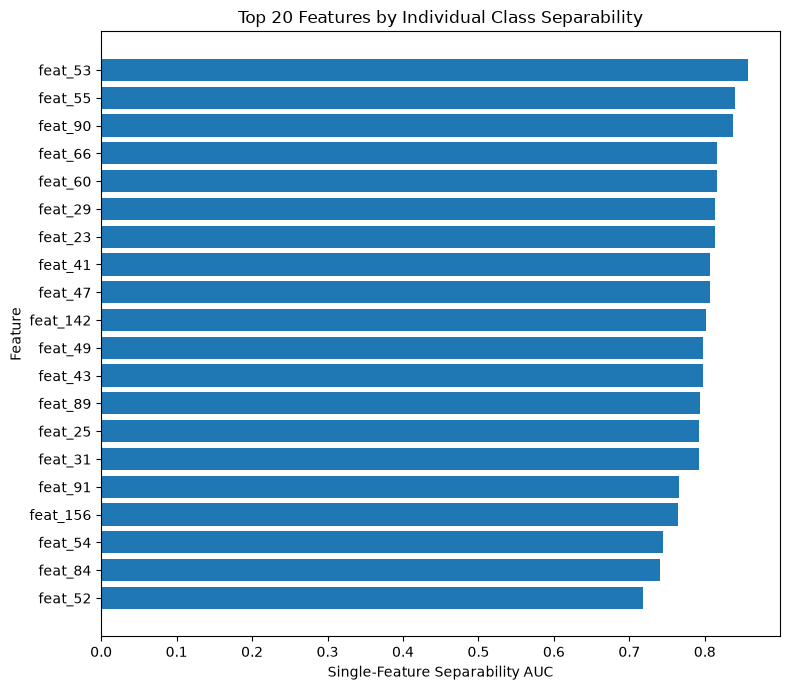

In [28]:
#Visualisation of top features
top_20 = (
    feature_ranking
    .head(20)
    .sort_values("separability_auc")
)

plt.figure(figsize=(8, 7))

plt.barh(
    top_20["feature"],
    top_20["separability_auc"]
)

plt.xlabel("Single-Feature Separability AUC")
plt.ylabel("Feature")
plt.title("Top 20 Features by Individual Class Separability")

plt.tight_layout()
plt.show()

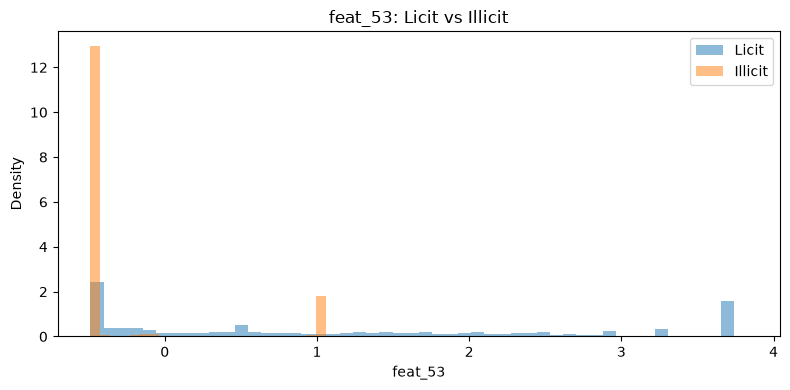

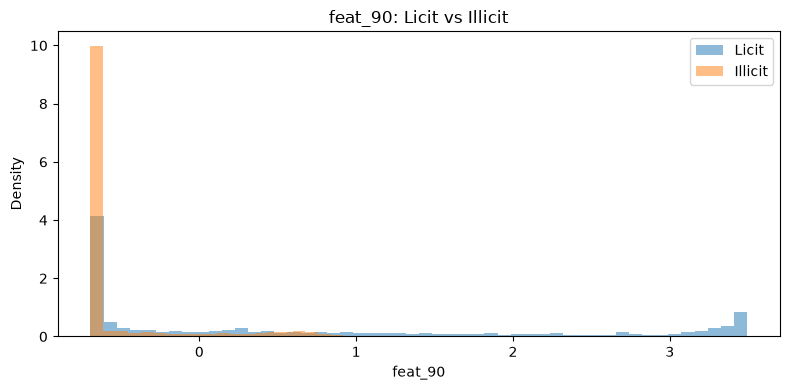

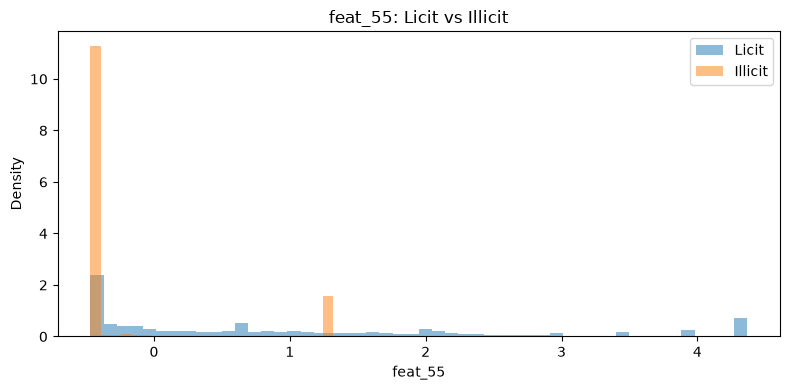

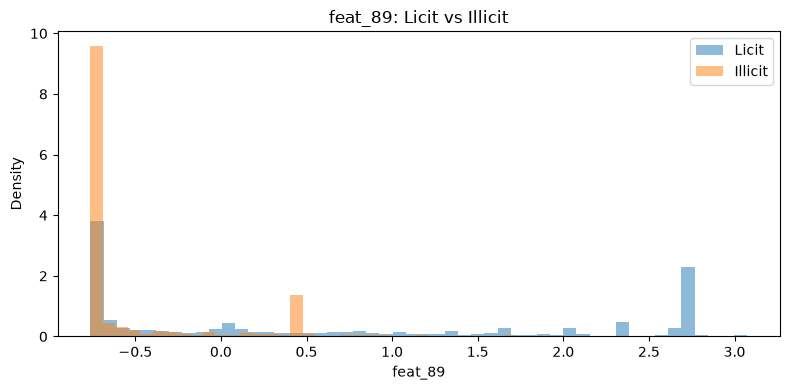

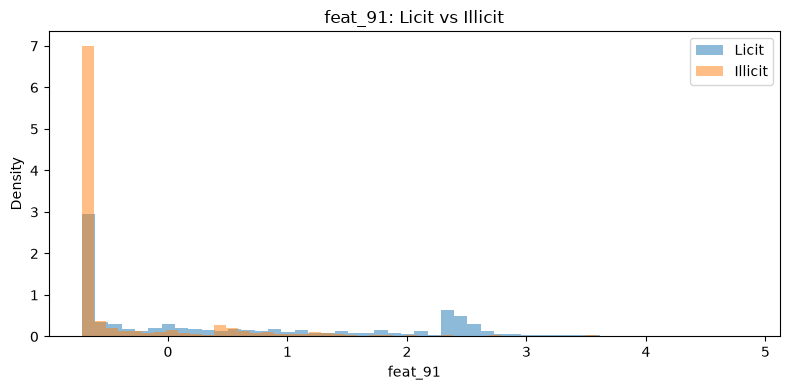

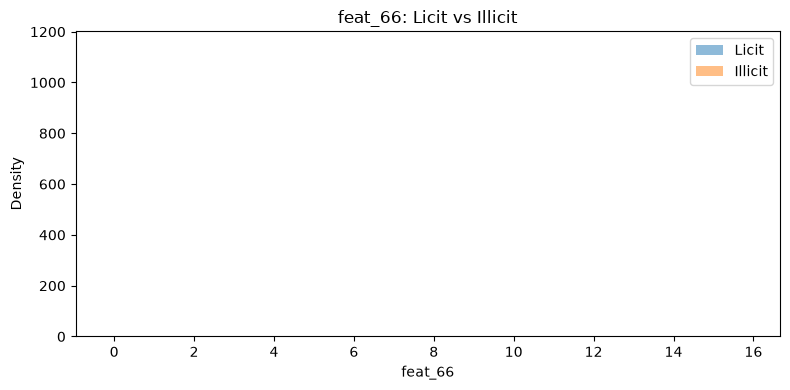

In [29]:
top_6 = top_features[:6]

for col in top_6:
    lower = labelled[col].quantile(0.01)
    upper = labelled[col].quantile(0.99)

    plot_data = labelled[
        labelled[col].between(lower, upper)
    ]

    plt.figure(figsize=(8, 4))

    plt.hist(
        plot_data.loc[plot_data[TARGET] == 0, col],
        bins=50,
        density=True,
        alpha=0.5,
        label="Licit"
    )

    plt.hist(
        plot_data.loc[plot_data[TARGET] == 1, col],
        bins=50,
        density=True,
        alpha=0.5,
        label="Illicit"
    )

    plt.xlabel(col)
    plt.ylabel("Density")
    plt.title(f"{col}: Licit vs Illicit")
    plt.legend()

    plt.tight_layout()
    plt.show()

**Correlation Among Top 20 Features**

We inspect correlation among the 20 features with the strongest licit/illicit relationship to identify strongly related or potentially redundant signals.

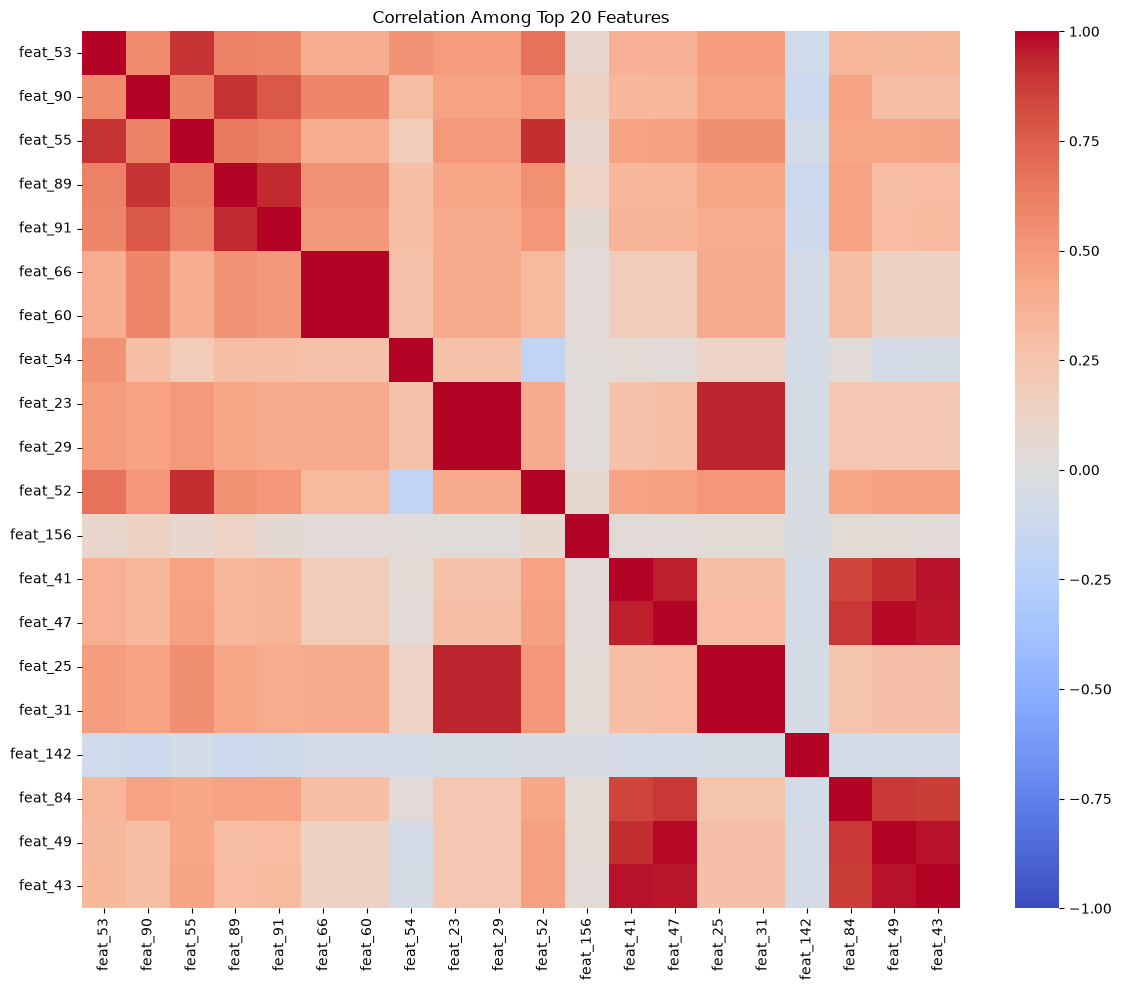

In [33]:
import seaborn as sns

# Use the existing ranked feature table when available.
if "top_features" not in globals():
    if "feature_ranking" in globals():
        top_features = feature_ranking.head(20)["feature"].tolist()
    elif "feature_screening" in globals():
        top_features = feature_screening.head(20)["feature"].tolist()
    else:
        raise NameError("Run the feature-screening/ranking cells above before this heatmap.")

plt.figure(figsize=(12, 10))
corr = labelled[top_features].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Among Top 20 Features")
plt.tight_layout()
plt.show()


2.6 Graph EDA

In [23]:
out_degree = edges["txId1"].value_counts()
in_degree = edges["txId2"].value_counts()

graph_stats = pd.DataFrame({
    "txId": pd.concat([
        edges["txId1"],
        edges["txId2"]
    ]).unique()
})

graph_stats["in_degree"] = (
    graph_stats["txId"]
    .map(in_degree)
    .fillna(0)
)

graph_stats["out_degree"] = (
    graph_stats["txId"]
    .map(out_degree)
    .fillna(0)
)

graph_stats["degree"] = (
    graph_stats["in_degree"]
    + graph_stats["out_degree"]
)

display(graph_stats.describe())

,txId,in_degree,out_degree,degree
count,2.037690e+05,203769.000000,203769.000000,203769.000000
mean,1.711310e+08,1.150101,1.150101,2.300203
std,1.104655e+08,3.911132,1.894740,4.328377
min,1.076000e+03,0.000000,0.000000,1.000000
25%,8.433452e+07,0.000000,1.000000,1.000000
50%,1.624375e+08,1.000000,1.000000,2.000000
75%,2.454798e+08,1.000000,1.000000,2.000000
max,4.032446e+08,284.000000,472.000000,473.000000


In [24]:
labelled_graph = labelled.merge(
    graph_stats,
    on="txId",
    how="left"
).fillna({
    "in_degree": 0,
    "out_degree": 0,
    "degree": 0
})

labelled_graph.groupby("label")[
    ["in_degree", "out_degree", "degree"]
].mean()

,in_degree,out_degree,degree
label,,,
0.0,1.830379,1.148382,2.978761
1.0,1.254391,0.754665,2.009056


***3. Preliminary EDA Findings***

The EDA reveals several important findings for this dataset.

1. Limited label availability: Only 22.03% of training transactions are labelled, suggesting that supervised models must be trained on a relatively small subset of the available data. Unlabelled transactions may still provide useful graph information.

2. Class imbalance: Among labelled transactions, 88.33% are licit and 11.67% are illicit. This highlights the importance of using evaluation metrics beyond accuracy, such as ROC-AUC and PR-AUC.

3. Temporal distribution: Training data spans time steps 1–35, while test data covers 36–49. The observed illicit rate among labelled transactions also varies considerably across time, suggesting potential temporal distribution shift. Chronological validation is therefore more appropriate than random splitting

4. Feature characteristics: The dataset contains 165 anonymised features, with no constant features and several highly skewed distributions. Univariate analysis identifies features such as feat_53, feat_55, and feat_90 as having strong individual class-separation ability.

5. Graph structure: Most connected nodes have relatively few connections, while a small number exhibit high connectivity. Licit transactions have higher average degrees than illicit transactions among labelled nodes, suggesting that graph-based features may provide additional predictive information.


Implications for modelling

The findings motivate a time-aware modelling approach that accounts for class imbalance and potential distribution shift. Initial experiments should establish tabular baselines using the available transaction features, followed by evaluating whether graph-derived features improve performance. Preprocessing and supervised feature selection must be fitted using only the relevant training period to avoid validation leakage.